<a href="https://colab.research.google.com/github/grsart/BiomolComp/blob/main/P11/05_ESM2_FineTuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prática 05 — Modelos de linguagem de proteínas: *embedding*, sondagem linear e *fine-tuning*

### Biologia Molecular Computacional · Aula de Aprendizado de Máquina

Nas práticas anteriores, as características foram calculadas **à mão**: um vetor one-hot da
sequência, a composição de bases, a distância entre genes. O modelo recebia esses descritores
prontos e aprendia apenas a combiná-los.

Esta prática fecha o arco da aula teórica. Vamos usar o **ESM-2**, um modelo de linguagem treinado
sobre ~65 milhões de sequências de proteínas do UniRef. Ele nunca viu um rótulo: foi treinado
apenas para prever resíduos mascarados dentro da própria sequência — aprendizado
**auto-supervisionado**. Dessa tarefa aparentemente boba ele extrai uma representação que carrega
estrutura, função e conservação evolutiva. É o mesmo princípio que está por trás do AlphaFold.

Vamos comparar três níveis de sofisticação no **mesmo problema e no mesmo conjunto de dados**:

| Nível | O que faz | O que o modelo aprende |
|---|---|---|
| 0. Linha de base | composição de aminoácidos (20 números) + regressão logística | só a combinação dos descritores que demos |
| 1. Sondagem linear (*probing*) | *embedding* do ESM-2 **congelado** + regressão logística | nada no ESM-2; aproveita a representação pronta |
| 2. *Fine-tuning* | ESM-2 + cabeça de classificação, **tudo** treinado | ajusta a própria representação à nossa tarefa |

**Problema biológico:** dada a sequência de aminoácidos, a proteína tem ou não um **segmento
transmembrana**?

> **Antes de começar:** vá em `Ambiente de execução → Alterar o tipo de ambiente de execução` e
> selecione **GPU (T4)**. Sem GPU, o nível 2 fica lento demais para a aula.
>
> Tempo estimado: ~20 min com GPU.

In [1]:
!pip install -q transformers
import os, time, urllib.request, urllib.parse
import numpy as np, matplotlib.pyplot as plt, torch
print("torch:", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NENHUMA (ative a GPU!)")

torch: 2.14.1+cu130 | GPU: Tesla T4


## 1. Montando o conjunto de dados a partir do UniProt

Nada de arquivo pronto: vamos consultar o UniProt pela API REST, como nas aulas de bases de dados.

* **Positivos:** proteínas humanas revisadas (Swiss-Prot) que têm ao menos uma anotação de
  característica `TRANSMEM`.
* **Negativos:** proteínas humanas revisadas **sem** nenhuma anotação `TRANSMEM`.

Restringimos o comprimento a 80–512 resíduos para o exemplo rodar rápido.

In [2]:
def uniprot(query, limite=1200):
    """Busca no UniProtKB e devolve [(acesso, sequência), ...]."""
    url = "https://rest.uniprot.org/uniprotkb/search?" + urllib.parse.urlencode(
        {"query": query, "format": "tsv", "fields": "accession,length,sequence", "size": "500"})
    linhas = []
    while url and len(linhas) < limite:
        req = urllib.request.Request(url, headers={"User-Agent": "aula-biomolcomp"})
        with urllib.request.urlopen(req, timeout=60) as r:
            texto = r.read().decode(); link = r.headers.get("Link")
        linhas += [l.split("\t") for l in texto.strip().split("\n")[1:]]
        url = link[link.index("<") + 1: link.index(">")] if link and 'rel="next"' in link else None
        time.sleep(0.3)
    return [(c[0], c[2]) for c in linhas[:limite]]

COMUM = "(reviewed:true) AND (organism_id:9606) AND (length:[80 TO 512])"
pos = uniprot(COMUM + " AND (ft_transmem:*)", limite=1200)
neg = uniprot(COMUM + " NOT (ft_transmem:*)", limite=1200)

acessos = [a for a, _ in pos] + [a for a, _ in neg]
seqs    = [s for _, s in pos] + [s for _, s in neg]
y       = np.array([1] * len(pos) + [0] * len(neg))

print("transmembrana: %d | sem transmembrana: %d" % (len(pos), len(neg)))
print("comprimento médio: %.0f resíduos" % np.mean([len(s) for s in seqs]))
print("exemplo:", acessos[0], seqs[0][:60], "...")

transmembrana: 1200 | sem transmembrana: 1200
comprimento médio: 314 resíduos
exemplo: A0PK11 MPGWFKKAWYGLASLLSFSSFILIIVALVVPHWLSGKILCQTGVDLVNATDRELVKFIGD ...


## 2. Dividir os dados — e por que não pode ser ao acaso

Sortear sequências ao acaso é o erro mais comum em aprendizado de máquina aplicado a proteínas:
parálogos e membros da mesma família caem dos dois lados, o conjunto de teste passa a conter
"paráfrases" do treino, e o desempenho relatado fica inflado.

A solução é dividir por **grupo de similaridade**: agrupamos as sequências parecidas e mandamos o
grupo inteiro para um lado só. Aqui usamos uma aproximação rápida — similaridade de cosseno entre
perfis de 3-mers — em vez de rodar CD-HIT ou MMseqs2, que seria o padrão em um trabalho real.

Vamos construir **as duas divisões** e comparar, no fim, o que cada uma reporta.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

def grupos_por_similaridade(seqs, k=3, limiar=0.45):
    """Agrupa sequências com perfis de k-mers parecidos (ligação simples)."""
    M = TfidfVectorizer(analyzer="word", token_pattern=r"\S+").fit_transform(
        [" ".join(s[i:i+k] for i in range(len(s) - k + 1)) for s in seqs])
    S = cosine_similarity(M).astype("float32"); np.fill_diagonal(S, 0)
    pai = list(range(len(seqs)))
    def raiz(a):
        while pai[a] != a: pai[a] = pai[pai[a]]; a = pai[a]
        return a
    for a, b in zip(*np.where(np.triu(S >= limiar, 1))):
        ra, rb = raiz(a), raiz(b)
        if ra != rb: pai[ra] = rb
    return np.array([raiz(i) for i in range(len(seqs))])

g = grupos_por_similaridade(seqs)
print("%d grupos para %d sequências (maior grupo: %d)" %
      (len(set(g.tolist())), len(seqs), np.bincount(g).max()))

# divisão POR GRUPO (a honesta)
rng = np.random.RandomState(0)
gs = np.array(sorted(set(g.tolist()))); rng.shuffle(gs)
treino_g = set(gs[:int(0.75 * len(gs))].tolist())
mask_tr = np.array([x in treino_g for x in g])
idx_tr, idx_te = np.where(mask_tr)[0], np.where(~mask_tr)[0]

# divisão ALEATÓRIA (para comparar no fim)
idx_tr_r, idx_te_r = train_test_split(np.arange(len(seqs)), test_size=0.25,
                                      random_state=0, stratify=y)

print("por grupo -> treino %d, teste %d (%.0f%% positivos no teste)" %
      (len(idx_tr), len(idx_te), 100 * y[idx_te].mean()))

2297 grupos para 2400 sequências (maior grupo: 9)
por grupo -> treino 1798, teste 602 (47% positivos no teste)


## 3. Nível 0 — a linha de base honesta

Vinte números por proteína: a fração de cada aminoácido. É o descritor "feito à mão" da aula
teórica, e para este problema ele já é forte — proteínas transmembrana são ricas em resíduos
hidrofóbicos.

**Toda comparação precisa de uma linha de base.** Se o modelo grande não superar estes 20 números,
ele não está agregando nada.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report)

AA = "ACDEFGHIKLMNPQRSTVWY"
def composicao(s):
    v = np.zeros(20)
    for ch in s:
        i = AA.find(ch)
        if i >= 0: v[i] += 1
    return v / max(len(s), 1)

X_comp = np.array([composicao(s) for s in seqs])

def avaliar(nome, X, itr, ite):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X[itr], y[itr])
    p = clf.predict_proba(X[ite])[:, 1]
    r = dict(acc=accuracy_score(y[ite], p > 0.5), auc=roc_auc_score(y[ite], p),
             ap=average_precision_score(y[ite], p))
    print("%-34s acc=%.3f  ROC AUC=%.3f  PR AUC=%.3f" % (nome, r["acc"], r["auc"], r["ap"]))
    return r, p

r0, p0 = avaliar("Nível 0: composição de AA", X_comp, idx_tr, idx_te)

Nível 0: composição de AA          acc=0.796  ROC AUC=0.895  PR AUC=0.904


## 4. Nível 1 — sondagem linear sobre o ESM-2 congelado

Agora trocamos os 20 números pela representação do ESM-2. O modelo fica **congelado**: ele só
transforma cada sequência em um vetor. Sobre esse vetor treinamos exatamente a mesma regressão
logística de antes — por isso o nome *sondagem linear*: estamos sondando o que a representação já
contém, sem ensinar nada ao modelo.

O ESM-2 devolve um vetor por **resíduo**. Para ter um vetor por **proteína**, fazemos a média sobre
os resíduos reais, ignorando os tokens de preenchimento (*padding*) — é o que a máscara de atenção
indica.

Usamos a menor versão (`esm2_t6_8M_UR50D`: 6 camadas, 320 dimensões, ~8 milhões de parâmetros).
Existem versões até 15 bilhões de parâmetros — e quanto maior, melhor a representação.

In [5]:
from transformers import AutoTokenizer, AutoModel

MODELO = "facebook/esm2_t6_8M_UR50D"   # troque por esm2_t12_35M_UR50D se sobrar tempo
MAX_LEN = 512
disp = "cuda" if torch.cuda.is_available() else "cpu"

tok = AutoTokenizer.from_pretrained(MODELO)
esm = AutoModel.from_pretrained(MODELO).to(disp).eval()
print("parâmetros do ESM-2: %.1f milhões | dimensão do embedding: %d" %
      (sum(p.numel() for p in esm.parameters()) / 1e6, esm.config.hidden_size))

@torch.no_grad()
def embeddings(lista, lote=16):
    saida = []
    for i in range(0, len(lista), lote):
        b = tok(lista[i:i+lote], return_tensors="pt", padding=True,
                truncation=True, max_length=MAX_LEN).to(disp)
        h = esm(**b).last_hidden_state                     # (lote, posições, 320)
        m = b["attention_mask"].unsqueeze(-1).float()      # ignora o padding
        saida.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
        if i % 320 == 0: print("  %d/%d" % (i, len(lista)), end="\r")
    return np.vstack(saida)

t0 = time.time()
X_esm = embeddings(seqs)
print("\nembeddings: %s em %.0f s" % (X_esm.shape, time.time() - t0))

config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 31.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


parâmetros do ESM-2: 7.5 milhões | dimensão do embedding: 320

embeddings: (2400, 320) em 22 s


In [6]:
r1, p1 = avaliar("Nível 1: ESM-2 congelado + logística", X_esm, idx_tr, idx_te)

Nível 1: ESM-2 congelado + logística acc=0.957  ROC AUC=0.991  PR AUC=0.991


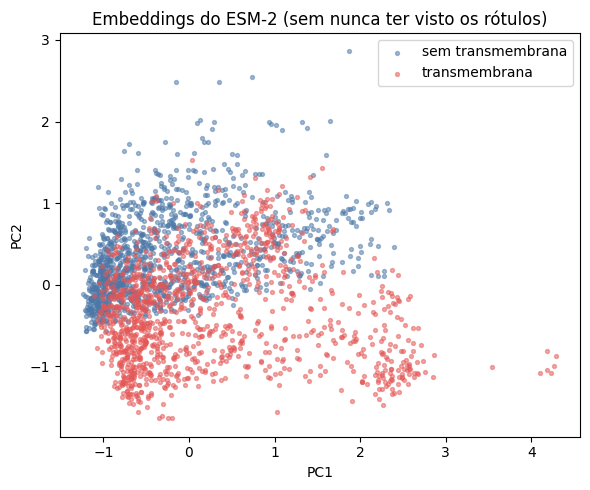

In [7]:
# O que a representação "vê"? Projeção em 2D pelo UMAP dos embeddings.
from sklearn.decomposition import PCA
Z = PCA(n_components=2).fit_transform(X_esm)
plt.figure(figsize=(6, 5))
for v, cor, rot in [(0, "#4C78A8", "sem transmembrana"), (1, "#E45756", "transmembrana")]:
    plt.scatter(Z[y == v, 0], Z[y == v, 1], s=8, alpha=0.5, c=cor, label=rot)
plt.legend(); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Embeddings do ESM-2 (sem nunca ter visto os rótulos)")
plt.tight_layout(); plt.show()

## 5. Nível 2 — *fine-tuning*

Agora descongelamos o ESM-2 e treinamos tudo junto: o modelo inteiro mais uma cabeça de
classificação. A representação deixa de ser genérica e se especializa na nossa tarefa.

O laço de treino abaixo é escrito à mão de propósito — ele é, linha por linha, o algoritmo da aula
teórica:

```
para cada lote:
    saída  = modelo(entrada)        # passo para frente
    perda  = criterio(saída, alvo)  # função de perda
    perda.backward()                # computa o gradiente
    otimizador.step()               # caminha na direção oposta ao gradiente
    otimizador.zero_grad()          # zera para o próximo passo
```

Três hiperparâmetros merecem atenção:

* **taxa de aprendizagem 2e-5** — mil vezes menor que a usada para treinar uma rede do zero. Os
  pesos já são bons; queremos ajustá-los, não destruí-los. Este é o erro número um em *fine-tuning*.
* **poucas épocas (3)** — com um modelo grande e poucos dados, o *overfitting* chega rápido.
* **lote de 8** — limitado pela memória da GPU.

In [8]:
from transformers import AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset

class Proteinas(Dataset):
    def __init__(self, indices): self.idx = indices
    def __len__(self): return len(self.idx)
    def __getitem__(self, i): return seqs[self.idx[i]], int(y[self.idx[i]])

def juntar(lote):
    s, r = zip(*lote)
    b = tok(list(s), return_tensors="pt", padding=True, truncation=True, max_length=MAX_LEN)
    b["labels"] = torch.tensor(r)
    return b

carga_tr = DataLoader(Proteinas(idx_tr), batch_size=8, shuffle=True,  collate_fn=juntar)
carga_te = DataLoader(Proteinas(idx_te), batch_size=16, shuffle=False, collate_fn=juntar)

modelo = AutoModelForSequenceClassification.from_pretrained(MODELO, num_labels=2).to(disp)
otim = torch.optim.AdamW(modelo.parameters(), lr=2e-5)

t0 = time.time()
for epoca in range(3):
    modelo.train(); perdas = []
    for b in carga_tr:
        b = {k: v.to(disp) for k, v in b.items()}
        saida = modelo(**b)              # passo para frente (a perda já vem calculada)
        saida.loss.backward()            # gradiente
        otim.step(); otim.zero_grad()    # passo e limpeza
        perdas.append(saida.loss.item())
    print("época %d | perda média de treino: %.4f | %.0f s" % (epoca + 1, np.mean(perdas), time.time() - t0))

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmForSequenceClassification LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


época 1 | perda média de treino: 0.2913 | 34 s
época 2 | perda média de treino: 0.0850 | 68 s
época 3 | perda média de treino: 0.0468 | 102 s


In [9]:
modelo.eval(); probs = []
with torch.no_grad():
    for b in carga_te:
        b = {k: v.to(disp) for k, v in b.items()}
        probs.append(torch.softmax(modelo(**b).logits, -1)[:, 1].cpu().numpy())
p2 = np.concatenate(probs)

r2 = dict(acc=accuracy_score(y[idx_te], p2 > 0.5),
          auc=roc_auc_score(y[idx_te], p2),
          ap=average_precision_score(y[idx_te], p2))
print("%-34s acc=%.3f  ROC AUC=%.3f  PR AUC=%.3f" % ("Nível 2: ESM-2 com fine-tuning", r2["acc"], r2["auc"], r2["ap"]))

Nível 2: ESM-2 com fine-tuning     acc=0.973  ROC AUC=0.990  PR AUC=0.991


## 6. Comparação final

In [10]:
import pandas as pd
tabela = pd.DataFrame([r0, r1, r2],
    index=["0 - composição de AA", "1 - ESM-2 congelado", "2 - ESM-2 fine-tuning"]).round(3)
tabela.columns = ["acurácia", "ROC AUC", "PR AUC"]
display(tabela)

print("\nMatriz de confusão do melhor modelo (linhas = real, colunas = predito):")
print(confusion_matrix(y[idx_te], p2 > 0.5))
print()
print(classification_report(y[idx_te], p2 > 0.5,
                           target_names=["sem TM", "transmembrana"], digits=3))

,acurácia,ROC AUC,PR AUC
0 - composição de AA,0.796,0.895,0.904
1 - ESM-2 congelado,0.957,0.991,0.991
2 - ESM-2 fine-tuning,0.973,0.990,0.991



Matriz de confusão do melhor modelo (linhas = real, colunas = predito):
[[309   8]
 [  8 277]]

               precision    recall  f1-score   support

       sem TM      0.975     0.975     0.975       317
transmembrana      0.972     0.972     0.972       285

     accuracy                          0.973       602
    macro avg      0.973     0.973     0.973       602
 weighted avg      0.973     0.973     0.973       602



## 7. O preço da divisão errada

Agora o experimento que justifica toda a seção 2: treinar e avaliar exatamente o mesmo modelo
simples, uma vez com a divisão por grupo e outra com a divisão aleatória.

In [11]:
print("mesma linha de base, duas divisões diferentes:")
_ = avaliar("  divisão POR GRUPO (honesta)", X_comp, idx_tr, idx_te)
_ = avaliar("  divisão ALEATÓRIA", X_comp, idx_tr_r, idx_te_r)
_ = avaliar("  ESM-2 congelado, POR GRUPO", X_esm, idx_tr, idx_te)
_ = avaliar("  ESM-2 congelado, ALEATÓRIA", X_esm, idx_tr_r, idx_te_r)

mesma linha de base, duas divisões diferentes:
  divisão POR GRUPO (honesta)      acc=0.796  ROC AUC=0.895  PR AUC=0.904
  divisão ALEATÓRIA                acc=0.823  ROC AUC=0.896  PR AUC=0.911
  ESM-2 congelado, POR GRUPO       acc=0.957  ROC AUC=0.991  PR AUC=0.991
  ESM-2 congelado, ALEATÓRIA       acc=0.947  ROC AUC=0.988  PR AUC=0.989


## Questões

**Q1.** Compare os três níveis. Quanto o ESM-2 congelado ganhou sobre os 20 números da composição de
aminoácidos? E quanto o *fine-tuning* ganhou sobre o modelo congelado? Qual dos dois saltos foi
maior, e o que isso diz sobre de onde vem o desempenho?

**Q2.** O ESM-2 nunca viu um rótulo de "transmembrana" durante o pré-treinamento — ele só aprendeu a
prever resíduos mascarados. Olhando o gráfico de PCA, como você explica que as duas classes já
apareçam separadas?

**Q3.** No nível 1 nós treinamos **zero** parâmetros do ESM-2; no nível 2, todos os ~8 milhões.
Compare o tempo de execução das duas células. Em que situação você escolheria a sondagem linear
mesmo tendo GPU disponível?

**Q4.** A taxa de aprendizagem do *fine-tuning* é 2e-5. Troque para 2e-3, rode de novo e descreva o
que acontece com a perda. Relacione com o slide das taxas de aprendizagem da aula teórica.

**Q5.** Na seção 7, a diferença entre a divisão aleatória e a divisão por grupo foi grande ou
pequena? Olhe o número de grupos encontrados (seção 2) e explique. Em que tipo de conjunto de dados
você esperaria uma diferença muito maior?

**Q6.** Truncamos as sequências em 512 resíduos. Para uma proteína com o segmento transmembrana
perto da extremidade C-terminal, que problema isso cria? Como você verificaria se isso está
afetando o resultado?

**Q7.** As classes aqui estão quase balanceadas porque nós as montamos assim. No proteoma humano, a
proporção real de proteínas com segmento transmembrana é bem menor. Se você aplicasse este
classificador ao proteoma inteiro, qual métrica da tabela ficaria otimista demais, e por quê?

---

### Para quem quiser ir além (não é necessário para a prática)

**Efeito de mutação sem nenhum treinamento.** O ESM-2 é um modelo de linguagem mascarado: dá para
mascarar uma posição e perguntar qual aminoácido ele espera ali. A razão entre a probabilidade do
mutante e a do tipo selvagem (*log-odds*) é um escore de efeito de mutação que funciona sem **nenhum**
dado rotulado — a abordagem *zero-shot* que hoje é referência em predição de variantes.

In [12]:
from transformers import AutoModelForMaskedLM

mlm = AutoModelForMaskedLM.from_pretrained(MODELO).to(disp).eval()

@torch.no_grad()
def escore_mutacao(seq, pos, wt, mut):
    """pos em numeração biológica (1 = primeiro resíduo)."""
    assert seq[pos - 1] == wt, "o resíduo selvagem não confere com a sequência"
    b = tok(seq, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(disp)
    i = pos  # +1 por causa do token inicial <cls>
    b["input_ids"][0, i] = tok.mask_token_id
    logp = torch.log_softmax(mlm(**b).logits[0, i], -1)
    return (logp[tok.convert_tokens_to_ids(mut)] - logp[tok.convert_tokens_to_ids(wt)]).item()

s = seqs[0]
print("sequência de teste:", acessos[0], "(%d resíduos)" % len(s))
for pos in [10, 25, 40]:
    wt = s[pos - 1]
    for mut in ["A", "D", "W"]:
        if mut != wt:
            print("  %s%d%s  escore = %+.2f" % (wt, pos, mut, escore_mutacao(s, pos, wt, mut)))
print("\nValores negativos = o modelo considera a mutação improvável (provavelmente deletéria).")

Loading weights:   0%|          | 0/107 [00:00<?, ?it/s]

sequência de teste: A0PK11 (232 resíduos)
  Y10A  escore = +0.95
  Y10D  escore = +0.07
  Y10W  escore = -0.21
  I25A  escore = +0.41
  I25D  escore = -3.07
  I25W  escore = -2.16
  C40A  escore = +2.15
  C40D  escore = +2.13
  C40W  escore = +0.48

Valores negativos = o modelo considera a mutação improvável (provavelmente deletéria).
